# 02. Classical Applied ML Feature Engineering
### Fixed Hand-Crafted Descriptors: Color Histograms + HOG + LBP
**Course:** Applied Machine Learning & Deep Learning (AML-DL)

---
## 1. Feature Representation Strategy
To build our Classical Applied ML baseline, we engineer a **1,634-dimensional fused feature representation** incorporating:
1. **HSV Color Histograms (48 dims):** Captures surface chromaticity independent of lighting intensity.
2. **HOG (1,568 dims):** Captures edge gradients, geometric contours, and silhouettes.
3. **LBP (18 dims):** Captures micro-surface texture roughness and periodicity.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.feature import hog, local_binary_pattern
from skimage.color import rgb2gray

REPO_ROOT = Path("..").resolve()
SPLITS_DIR = REPO_ROOT / "splits"
FEATURES_PATH = REPO_ROOT / "data" / "features_aml.npz"

train_df = pd.read_csv(SPLITS_DIR / "train.csv")


## 2. Inspecting the Feature Dictionary
Review the theoretical structure and vulnerability profile of each engineered descriptor block.


In [2]:
feat_dict = pd.read_csv(REPO_ROOT / "results" / "metrics" / "feature_dictionary.csv")
display(feat_dict)


,Feature_Block,Color_Space,Channels,Bins_Per_Channel,Dimensions,Invariant_To,Vulnerable_To,Bins_Per_Cell,Pattern_Type
0,Color Histogram,HSV,"H, S, V",16.0,48,"Scale, translation","Specular reflections, illumination shifts",NaN,NaN
1,HOG (Histogram of Gradients),Grayscale,Luminance,NaN,1568,Global illumination gradients,"Severe crumpling, crushing, 3D rotations",8.0,NaN
2,LBP (Local Binary Patterns),Grayscale,Luminance,NaN,18,Monotonic gray-scale changes,"Blur, smooth non-textured surfaces",NaN,"Uniform (P=16, R=2)"


## 3. Visualizing Descriptors on a Single Test Sample
We extract and plot Color Histograms, HOG contours, and LBP texture maps side-by-side.


/opt/anaconda3/lib/python3.13/site-packages/skimage/feature/texture.py:385: UserWarning: Applying `local_binary_pattern` to floating-point images may give unexpected results when small numerical differences between adjacent pixels are present. It is recommended to use this function with images of integer dtype.
  warnings.warn(


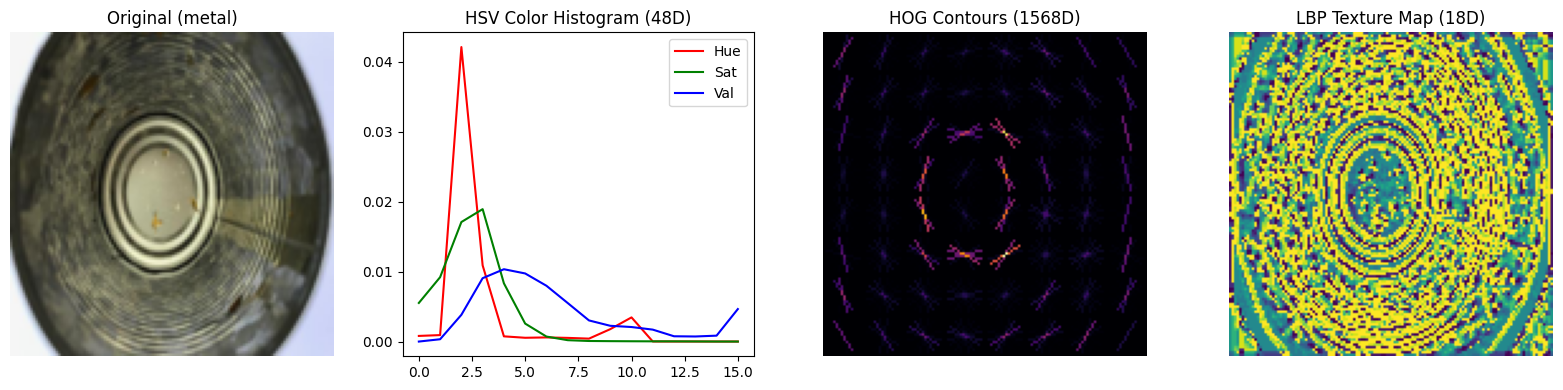

In [3]:
sample_row = train_df[train_df["class_name"] == "metal"].iloc[0]
sample_path = REPO_ROOT / sample_row["filepath"]

with Image.open(sample_path) as img:
    img_rgb = img.convert("RGB").resize((128, 128), Image.Resampling.BILINEAR)
    img_np = np.array(img_rgb)

# 1. Color Histogram (HSV)
img_hsv = np.array(img_rgb.convert("HSV"))
h_hist, _ = np.histogram(img_hsv[:, :, 0], bins=16, range=(0, 255), density=True)
s_hist, _ = np.histogram(img_hsv[:, :, 1], bins=16, range=(0, 255), density=True)
v_hist, _ = np.histogram(img_hsv[:, :, 2], bins=16, range=(0, 255), density=True)

# 2. HOG
img_gray = rgb2gray(img_np)
hog_feats, hog_image = hog(
    img_gray, orientations=8, pixels_per_cell=(16, 16),
    cells_per_block=(2, 2), block_norm='L2-Hys', visualize=True
)

# 3. LBP
lbp_map = local_binary_pattern(img_gray, P=16, R=2, method="uniform")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img_rgb)
axes[0].set_title(f"Original ({sample_row['class_name']})")
axes[0].axis("off")

axes[1].plot(h_hist, color="red", label="Hue")
axes[1].plot(s_hist, color="green", label="Sat")
axes[1].plot(v_hist, color="blue", label="Val")
axes[1].set_title("HSV Color Histogram (48D)")
axes[1].legend()

axes[2].imshow(hog_image, cmap="inferno")
axes[2].set_title(f"HOG Contours ({len(hog_feats)}D)")
axes[2].axis("off")

axes[3].imshow(lbp_map, cmap="viridis")
axes[3].set_title("LBP Texture Map (18D)")
axes[3].axis("off")

plt.tight_layout()
plt.show()


## 4. Verification of Cached Features
Verify that precomputed feature tensors match expected split lengths and dimensionalities.


In [4]:
features = np.load(FEATURES_PATH)
for k in features.files:
    print(f"Array '{k}': shape = {features[k].shape}, dtype = {features[k].dtype}")


Array 'X_train': shape = (1763, 1634), dtype = float32
Array 'y_train': shape = (1763,), dtype = int64
Array 'X_val': shape = (378, 1634), dtype = float32
Array 'y_val': shape = (378,), dtype = int64
Array 'X_test': shape = (378, 1634), dtype = float32
Array 'y_test': shape = (378,), dtype = int64
